# 쇼핑몰 단골 찾기
멀티모달 피처 엔지니어링 · EDA · RFM 고객 세분화

실제 거래와 **별도 생성한 합성 이미지**를 결합한 실습이다. 이미지는 실제 상품 사진이 아니므로 이미지·매출의 관계를 비즈니스 근거로 사용하지 않는다. 데이터: Chen (2015), [UCI Online Retail](https://doi.org/10.24432/C5BW33), CC BY 4.0. 원본 541,909행, 8열 전체를 사용한다.

In [1]:
from pathlib import Path
import sys
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.pipeline import DataAnalyzer
from scripts.build_report import create_figures

pd.set_option('display.max_columns', 20)
a = DataAnalyzer(ROOT / 'data/raw/transactions.csv')
a.load_data()
print('Rows / raw columns:', a.raw.shape)
display(a.raw.head())

Rows / raw columns: (541909, 8)


,order_id,product_id,product_name,quantity,order_date,price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:25:59.999999638,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:25:59.999999638,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:25:59.999999638,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:25:59.999999638,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:25:59.999999638,3.39,17850,United Kingdom


## 1. 데이터 구조와 결측
숫자(가격·수량), 텍스트(상품명), 범주(국가), 날짜를 확인한다. 원본 고객 ID 누락 135,080행은 RFM에서 제외한다. 따라서 분석 결과는 고객 식별이 가능한 거래를 대표하며 전체 방문 고객을 대표하지 않는다.

In [2]:
from scripts.report_evidence import load_config, correlation_pairs
settings = load_config(ROOT / 'outputs/config_used.json')
a.analysis_config = settings
a.raw.info()
display(a.raw.dtypes.astype(str).value_counts().rename('column_count').to_frame())
display(a.raw.describe(include='all'))
display(pd.DataFrame({'raw_missing': a.raw.isna().sum(), 'eda_missing_before': a.df.isna().sum()}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   order_id      541909 non-null  string        
 1   product_id    541909 non-null  string        
 2   product_name  540455 non-null  string        
 3   quantity      541909 non-null  int64         
 4   order_date    541909 non-null  datetime64[ns]
 5   price         541909 non-null  float64       
 6   customer_id   406829 non-null  string        
 7   country       541909 non-null  string        
dtypes: datetime64[ns](1), float64(1), int64(1), string(5)
memory usage: 33.1 MB


,column_count
string,5
int64,1
datetime64[ns],1
float64,1


,order_id,product_id,product_name,quantity,order_date,price,customer_id,country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829,541909
unique,25900,4070,4223,NaN,NaN,NaN,4372,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,17841,United Kingdom
freq,1114,2313,2369,NaN,NaN,NaN,7983,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,NaN,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:25:59.999999638,-11062.060000,NaN,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00.000000512,1.250000,NaN,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:16:59.999999744,2.080000,NaN,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:26:59.999999744,4.130000,NaN,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:49:59.999999721,38970.000000,NaN,NaN


,raw_missing,eda_missing_before
country,0.0,0
customer_id,135080.0,135080
order_date,0.0,0
order_id,0.0,0
price,0.0,2517
price_was_invalid,NaN,0
product_id,0.0,0
product_name,1454.0,1454
quantity,0.0,0


## 2. 그룹별 결측치 대치
0 이하 가격을 EDA에서 결측으로 바꾸고 **동일 상품 ID별 중앙값 → 전체 중앙값** 순서로 대치한다. 대치 대상은 2,517행이다. 상품명은 동일 상품의 관측값을 앞뒤로 채우고 남으면 UNKNOWN PRODUCT를 사용한다. 고객 ID와 거래일은 채우지 않으며, RFM은 대치 이전 원본을 사용한다.

In [3]:
a.handle_missing(strategy=settings['missing_strategy'], group_col=settings['missing_group_col'])
print('Imputed price rows:', a.audit['imputed_price'])
print('Imputation audit:', a.audit['price_imputation'])
display(a.imputation_details['price'].sort_values('missing_ratio', ascending=False).head(10))
display(a.df.isna().sum().rename('remaining_missing').to_frame())

Imputed price rows: 2517
Imputation audit: {'strategy': 'median', 'group_col': 'product_id', 'groups': 4070, 'groups_with_missing': 1420, 'all_missing_groups': 132, 'group_imputed_rows': 2383, 'global_fallback_rows': 134, 'global_reference_value': 2.08, 'observed_variance_ddof0': 8951.929091891936, 'filled_variance_ddof0': 9362.06750527732}


,total_rows,observed_rows,reference_value,missing_rows,missing_ratio,uses_global_fallback
product_id,,,,,,
21337,1,0,NaN,1,1.0,True
72793,1,0,NaN,1,1.0,True
21511,1,0,NaN,1,1.0,True
20849,1,0,NaN,1,1.0,True
20850,1,0,NaN,1,1.0,True
47563B,1,0,NaN,1,1.0,True
20863,1,0,NaN,1,1.0,True
20864,1,0,NaN,1,1.0,True
84664,1,0,NaN,1,1.0,True


,remaining_missing
order_id,0
product_id,0
product_name,0
quantity,0
order_date,0
price,0
customer_id,135080
country,0
price_was_invalid,0


## 3. NumPy 멀티모달 피처
(N,H,W,C) 배열의 축 (1,2,3)을 한 번에 축약해 이미지별 평균·표준편차를 계산한다. 전체 이미지를 벡터로 처리하므로 이미지/픽셀 for 문이 없다. 표준편차는 모집단 기준 ddof=0이고, 텍스트는 길이와 공백 기준 단어 수로 수치화한다. 추가로 float32 변환 후 인접 픽셀 절댓값 차이로 엣지를 계산해 uint8 차감의 오버플로를 피한다.

In [4]:
with np.load(ROOT / 'data/image_fixtures.npz', allow_pickle=False) as fixture:
    print('Synthetic image batch:', fixture['images'].shape)
    a.engineer_features(fixture['product_ids'], fixture['images'])
display(a.df[['product_name', 'name_length', 'name_word_count', 'image_mean', 'image_std', 'image_edge']].head())

Synthetic image batch: (4070, 16, 16, 3)


,product_name,name_length,name_word_count,image_mean,image_std,image_edge
0,WHITE HANGING HEART T-LIGHT HOLDER,34,5,184.285156,27.168085,28.428473
1,WHITE METAL LANTERN,19,3,90.304688,43.232666,27.168056
2,CREAM CUPID HEARTS COAT HANGER,30,5,136.358078,60.261200,26.134027
3,KNITTED UNION FLAG HOT WATER BOTTLE,35,6,138.721359,67.939812,26.910416
4,RED WOOLLY HOTTIE WHITE HEART.,30,5,62.131512,26.663307,27.254168


## 4. 직접 구현한 IQR 이상치 탐지
Q1−1.5×IQR 미만 또는 Q3+1.5×IQR 초과를 표시한다. 가격 Q1=£1.25, Q3=£4.13, 상한=£8.45이며 이상치는 39,854행이다. 고가 상품은 유효한 구매일 수 있으므로 자동 삭제하지 않는다. 전후 박스플롯은 파생 열 클리핑의 영향만 보여준다.

In [5]:
outliers = a.detect_outliers('price', threshold=settings['iqr_threshold'], treatment='clip')
print(a.audit['price_iqr'])
display(outliers[['product_id', 'price', 'price_clipped']].head())

{'q1': 1.25, 'q3': 4.13, 'iqr': 2.88, 'lower': -3.0700000000000003, 'upper': 8.45, 'count': 39854}


,product_id,price,price_clipped
16,22622,9.95,8.45
45,POST,18.00,8.45
65,21258,10.95,8.45
141,D,27.50,8.45
151,22839,14.95,8.45


## 5. 기술 통계와 상관분석
아래 통계는 대치된 EDA 전체 상품 행 기준이며 반품 수량도 포함한다. 가격 평균 £4.71, 중앙값 £2.08, 표준편차 £96.76, Q1 £1.25, Q3 £4.13이다. 평균과 중앙값의 차이는 고가 꼬리의 영향을 보여주므로 대표 가격은 중앙값과 사분위수도 함께 본다.

① 수량–금액 Pearson r=0.7468. 금액=가격×수량이라는 정의와 대량 주문의 영향이 있으므로 수량과 금액을 독립적인 수요 지표처럼 해석하면 안 된다.

② 가격–수량 Pearson r=-0.0013. 이 선형 상관만으로 가격 인하가 수요를 늘린다고 결론낼 수 없으므로 상품별·기간별 통제 분석이 필요하다. 합성 이미지의 상관은 생성 과정에 따른 우연이며 상품 사진의 효과에 대한 근거가 아니다.

In [6]:
display(a.summary_statistics())
correlation_columns = ['price', 'quantity', 'amount', 'name_length', 'image_mean', 'image_std']
display(a.df[correlation_columns].corr())
# Explicit series.corr calculations for at least two distinct pairs
display(correlation_pairs(a))

,count,mean,std,min,25%,50%,75%,max
price,541909.0,4.711275,96.757867,0.001,1.25,2.08,4.13,38970.0
quantity,541909.0,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
amount,541909.0,17.960425,463.157021,-168469.6,3.44,9.78,17.4,185280.0
name_length,541909.0,26.640473,5.453473,1.0,23.0,27.0,31.0,35.0
image_mean,541909.0,124.087151,32.110111,39.769531,102.061195,124.54557,145.496094,209.753906
image_std,541909.0,48.938133,15.147091,23.797129,36.105228,47.441898,61.418949,89.786659


,price,quantity,amount,name_length,image_mean,image_std
price,1.000000,-0.001282,-0.131163,-0.045513,0.004746,-0.004580
quantity,-0.001282,1.000000,0.746752,0.000941,-0.001392,-0.001297
amount,-0.131163,0.746752,1.000000,-0.001154,0.002659,-0.001656
name_length,-0.045513,0.000941,-0.001154,1.000000,-0.052287,0.001295
image_mean,0.004746,-0.001392,0.002659,-0.052287,1.000000,0.021431
image_std,-0.004580,-0.001297,-0.001656,0.001295,0.021431,1.000000


,x,y,n,pearson_r
0,quantity,amount,541909,0.746752
1,price,quantity,541909,-0.001282
2,price,amount,541909,-0.131163


## 6. RFM과 회계 기준
빈도는 상품 행 수가 아닌 `order_id.nunique()`이고 금액은 원본 양수 거래의 합이다. 기준일 2011-12-09, 유효 구매 397,884행, 고객 4,338명이다. 취소·비양수 가격/수량·식별자/날짜 결측은 제외한다. 반품 차감 순매출이 아니므로 수익성 판단에는 추가 데이터가 필요하다.

동점은 평균 백분위로 같은 점수를 부여한다. 우선순위는 VIP(R/F/M≥4), Churned(R≤2), New(R≥4·주문 1회), Loyal(F≥3), Potential(나머지)이다.

In [7]:
rfm = a.calculate_rfm(reference_date=settings['reference_date'])
segment_summary = rfm.groupby('segment').agg(customers=('monetary', 'size'), mean_recency=('recency', 'mean'), mean_frequency=('frequency', 'mean'), mean_monetary=('monetary', 'mean'), gross_purchases=('monetary', 'sum'))
display(rfm.head())
display(segment_summary.round(2))
print('Reference date:', a.reference_date)
print('RFM customers:', len(rfm), 'Segments:', rfm.segment.nunique())

,last_purchase,frequency,monetary,recency,r_score,f_score,m_score,segment
customer_id,,,,,,,,
12346,2011-01-18 10:00:59.999999981,1,77183.60,325,1,1,5,Churned
12347,2011-12-07 15:52:00.000000111,7,4310.00,2,5,5,5,VIP
12348,2011-09-25 13:12:59.999999814,4,1797.24,75,2,4,4,Churned
12349,2011-11-21 09:50:59.999999916,1,1757.55,18,4,1,4,New
12350,2011-02-02 16:00:59.999999981,1,334.40,310,1,1,2,Churned


,customers,mean_recency,mean_frequency,mean_monetary,gross_purchases
segment,,,,,
Churned,1727,191.60,1.98,777.43,1342624.23
Loyal,1169,32.36,3.52,1441.20,1684766.78
New,236,18.42,1.00,325.84,76897.84
Potential,295,52.46,1.00,402.42,118712.85
VIP,911,11.86,11.50,6244.13,5688406.20


Reference date: 2011-12-09 00:00:00
RFM customers: 4338 Segments: 5


## 7. 필수 6종 시각화
히스토그램·박스플롯의 가격은 양수 대치값을 사용한다. 산점도와 월별 라인차트는 원본 유효 구매만 사용한다. 로그 축과 log10 변환은 축 레이블에 명시했다. 이미지 피처가 합성이라는 점도 히트맵에 표시했다.

In [8]:
%matplotlib inline

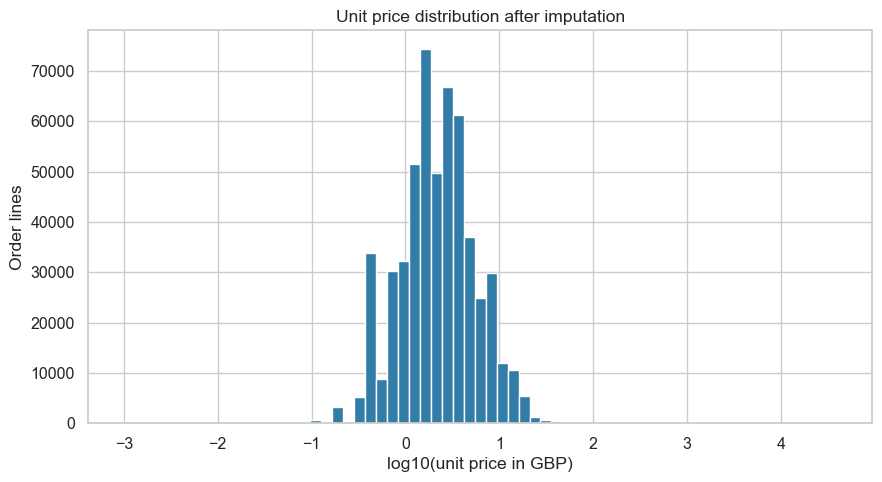

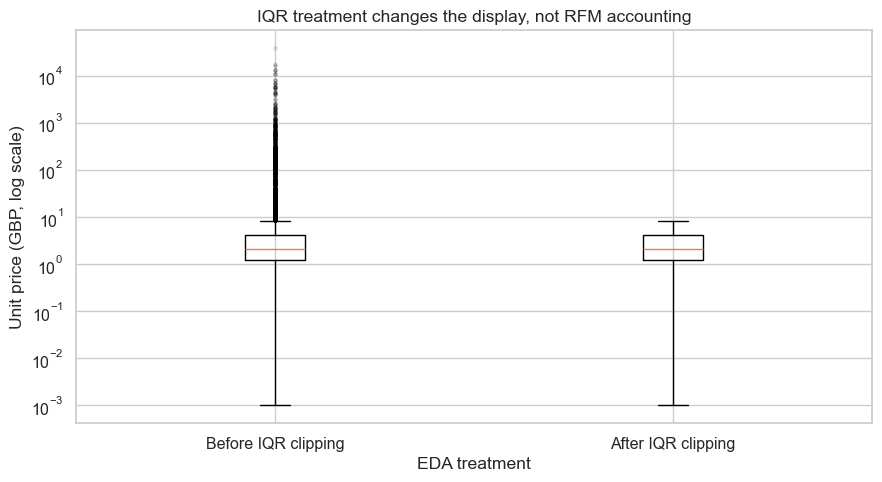

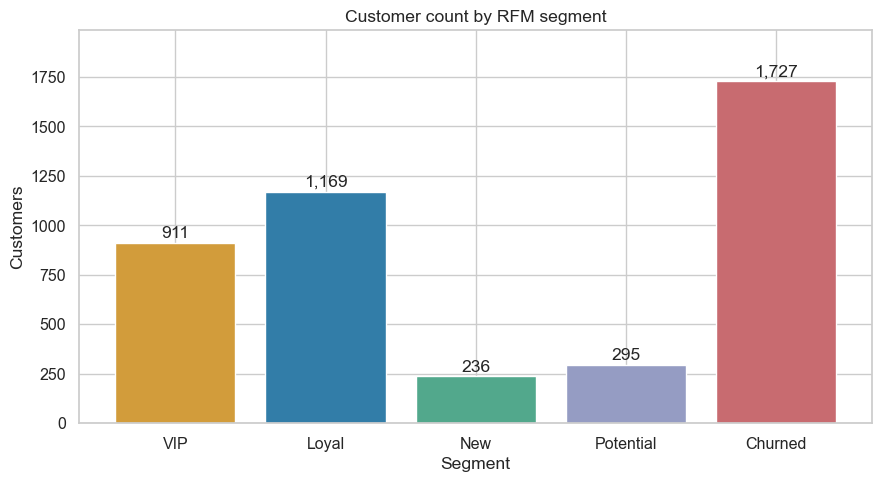

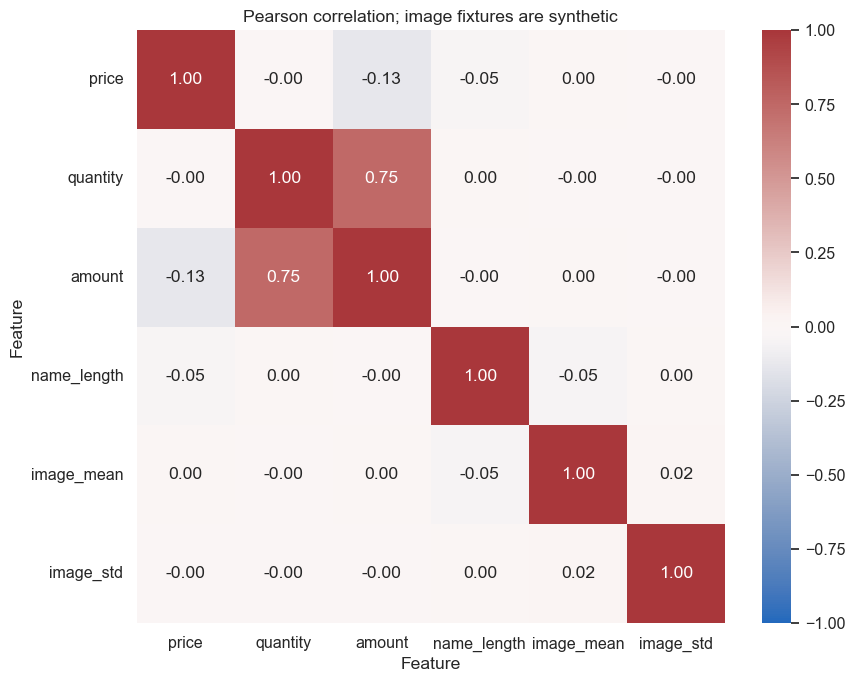

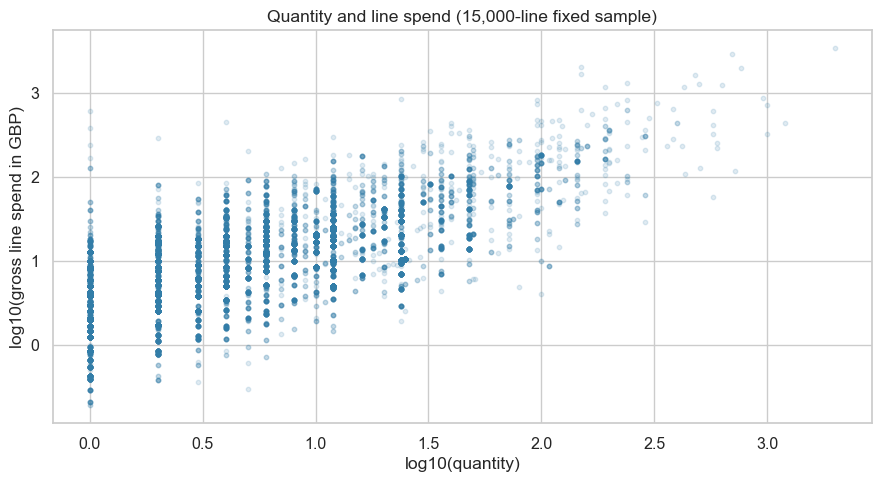

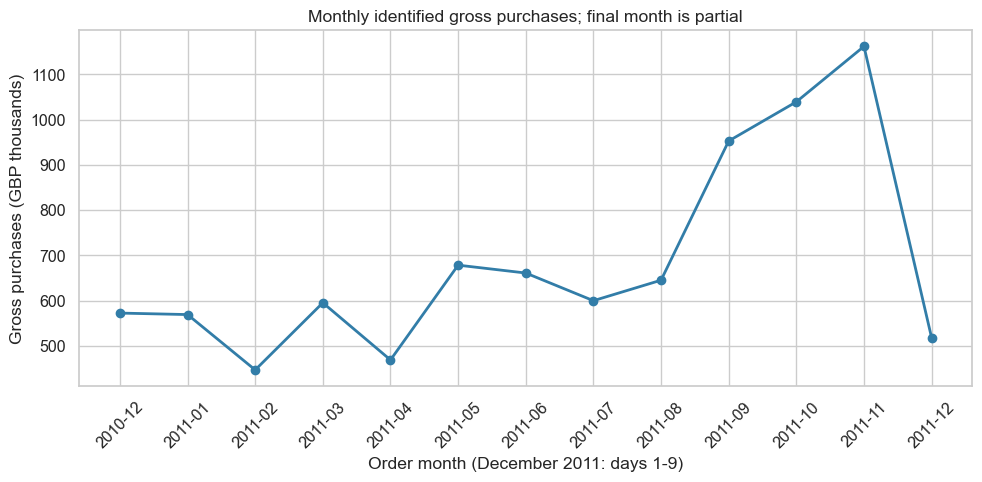

In [9]:
figures = create_figures(a, rfm)
for name, fig in figures.items():
    display(fig)
    plt.close(fig)

### 시계열 해석
2011년 11월 식별 고객 총 구매액은 £1,161,817.38, 2011년 12월은 £518,192.79이다. 12월은 1~9일만 관측했으므로 월 합계 감소를 매출 부진으로 해석할 수 없다. 동일 일수 또는 전년 동기 비교가 필요하다. 이 시계열은 2010~2011년 이력으로 현재 시장을 설명하지 않는다.

## 8. 세그먼트별 실행 전략

**VIP 유지** — (근거) VIP 911명은 고객의 21.0%이지만 식별 고객 총 구매액의 63.8%를 차지한다. (실행) VIP 고객을 대상으로 우선 재입고 알림과 전담 응대 혜택을 제공하여 재구매 유지율 개선을 목표로 한다. (검증) 실제 순이익·반품·캠페인 노출 데이터가 필요하며, 무작위 대조군 대비 60일 재구매율과 공헌이익이 개선되지 않으면 전략을 기각한다.

**휴면 위험 고객 복귀** — (근거) Churned 1,727명(39.8%)의 평균 미구매 기간은 191.6일이다. (실행) Churned 중 과거 구매액이 높은 고객에게 개인화 재입고 안내를 보내고, 소규모 쿠폰 실험으로 30일 복귀율 개선을 목표로 한다. (검증) Churned는 상대적 최근성 점수에 붙인 이름이며 실제 이탈 확정이 아니다. 수신 동의·시즌성·할인 비용 데이터를 확보하고 대조군 대비 증분 이익으로 검증한다.

**첫 관측 구매 고객의 두 번째 주문** — (근거) New 236명은 관측 기간 주문이 1회이며 평균 구매액은 £325.84이다. (실행) 최근 1회 구매 고객에게 구매 7~14일 뒤 관련 상품 안내를 제공해 두 번째 주문 전환율 개선을 목표로 한다. (검증) 가입일과 관측 이전 구매 이력이 없으므로 진짜 신규 고객 여부는 알 수 없다. 추가 이력을 확인하고 캠페인 대조 실험으로 30일 두 번째 구매율을 비교한다.

## 9. 결과 검증과 한계
세그먼트 수·고객 유일성·일수 비음수·원본 구매액 보존을 검증한다. 결측 제외 사유는 중복될 수 있으므로 항목별 제외 건수를 더해서 전체 제외 행 수로 사용하지 않는다. 가입 시점, 실제 상품 이미지, 마진, 노출/전환 이력, 고객 연락처는 제공되지 않았다.

In [10]:
purchase = a.valid_transactions()
assert len(rfm) == purchase.customer_id.nunique()
assert rfm.index.is_unique and rfm.recency.ge(0).all()
assert rfm.segment.nunique() >= 4
assert np.isclose(rfm.monetary.sum(), purchase.amount.sum())
assert a.df.shape[0] >= 1000 and a.raw.shape[1] >= 8
assert a.df[['price', 'image_mean', 'image_std', 'name_length']].notna().all().all()
print('All dataset acceptance checks passed.')
display(pd.Series(a.audit, name='value').to_frame())

All dataset acceptance checks passed.


,value
raw_rows,541909
exact_duplicate_rows,5268
imputed_price,2517
price_imputation,"{'strategy': 'median', 'group_col': 'product_i..."
price_iqr,"{'q1': 1.25, 'q3': 4.13, 'iqr': 2.88, 'lower':..."
missing_customer_rows,135080
cancel_or_nonpositive_qty_rows,10624
nonpositive_or_missing_price_rows,2517
invalid_date_rows,0
valid_purchase_rows,397884


## 10. 피드백 보완: 해석·성능·검증·ML 설계

## 실행 증거와 평가 항목 안내

- [실행된 노트북](../notebooks/analysis_report.ipynb): 모든 코드 셀의 실행 번호와 6개 PNG 출력을 저장한다.
- [전체 실행 로그](../outputs/execution.log), [실행 상태·버전·SHA-256](../outputs/execution_summary.json): 성공 여부와 실제 실행 셀 수·오류 수를 확인한다.
- [차트 6종](../outputs/figures), [차트 제목·축 레이블·파일 체크섬](../outputs/figure_manifest.json): 파일이 실제 존재하는지 추적할 수 있다.
- [19개 평가 항목 대응표](../outputs/evaluation_evidence.md): 요구 사항과 검토할 파일을 한곳에 모았다.
- 원본 정규화 후 타입 분포: `string` 5열, `int64` 1열, `datetime64[ns]` 1열, `float64` 1열. 원본 8열에서 날짜·숫자·문자/범주를 다루고 별도 배열 이미지 피처를 결합한다.

## 핵심 메서드와 설정

| 메서드 | 책임 | 원본 회계 데이터 변경 |
| --- | --- | --- |
| `load_data()` | 8열 검증·숫자/날짜 변환·원본/EDA 분리 | 로드 시 원본 사본 생성 |
| `handle_missing()` | 평가 기준 호환 진입점; 아래 메서드에 위임 | 없음 |
| `handle_missing_values()` | 그룹 통계 대치·전체 폴백·그룹별 결측 감사 | 없음 |
| `image_features()` / `engineer_features()` | 벡터 이미지 통계·텍스트 길이/단어 수 | 없음 |
| `detect_outliers()` | IQR 플래그·별도 클리핑 열 | 없음 |
| `calculate_rfm()` | 식별 가능한 원본 양수 구매의 고객별 RFM | 없음 |

파라미터는 [config.json](../config.json)에 모았다. `--config path/to/override.json`으로 대치 전략/그룹, IQR 배수, RFM 기준일, 산점도 표본·seed와 벤치마크 크기를 변경할 수 있다. 메서드 인자로 직접 전달하는 방식도 유지한다. `outputs/config_used.json`은 이번 실행의 실제 설정이다.

## 상관계수 2쌍 이상과 기술 통계 해석

분석 범위는 **대치 후 전체 상품 행(반품 포함)**이며 클리핑 전 `price`, `quantity`, `amount`다. [상관계수 직접 계산 결과](../outputs/correlation_pairs.csv)에서 각 쌍의 표본 수와 값을 확인할 수 있다.

| 변수 쌍 | Pearson r | 해석과 시사점 |
| --- | --- | --- |
| quantity / amount | 0.746752 | 금액=가격×수량의 기계적 관계와 대량 주문이 영향을 준다. 수량과 금액을 서로 독립적인 수요 근거로 중복 계산하지 않는다. |
| price / quantity | -0.001282 | 전체 행에서 선형 관계가 약해도 개별 상품의 가격 탄력성이 없다는 뜻은 아니다. 상품·기간·반품 여부를 통제한 분석이 필요하다. |
| price / amount | -0.131163 | 음수 반품과 고가 행의 영향이 섞인다. 거래 부호를 나눈 민감도 분석 없이 가격의 매출 효과로 해석하지 않는다. |

가격 평균 £4.7113, 중앙값 £2.0800, 표준편차 £96.7579, Q1 £1.25, Q3 £4.13다. 오른쪽 꼬리에 민감한 평균·표준편차와 함께 중앙값·사분위수를 제시해야 대표 가격을 과장하지 않는다. [전체 기술 통계](../outputs/descriptive_statistics.csv)에는 수량·금액·텍스트·이미지 통계도 포함한다.

## 그룹별 결측 대치의 근거와 위험

대상 가격 결측/비양수는 2,517행(0.464%)이다. 총 4,070개 상품 그룹 중 1,420개에서 대치가 필요했다. 그룹 내 관측 가격으로 2,383행을 채우고, 가격 전체가 결측인 132개 그룹의 134행은 전체 median £2.0800로 대치했다. 상품 `23595`의 결측률은 100.0%(2/2행)다. [상품별 결측률·관측 수·대치값](../outputs/imputation_by_product.csv)에 전체 그룹을 기록한다.

상품마다 가격대가 달라 동일 상품 통계가 전체 통계보다 자연스러운 기준이다. 기본 중앙값은 비싼 꼬리값의 영향을 줄이지만 **결측이 무작위라는 사실을 보장하지 않는다.** 예를 들어 가격 10·20에서 결측을 15로 채우면 모집단 분산이 25에서 16.67로 줄어든다(설명용 예시). 그룹 내 분산이 줄어 그룹 간 차이가 상대적으로 과장되고, 할인 기간에만 가격이 누락되었다면 해당 그룹 가격을 과대 추정할 수 있다. 전체 폴백은 희소·신규 상품의 특성을 지울 수도 있다.

실제 관측 가격만의 모집단 분산은 8951.9291, 대치 후 전체 분산은 9362.0675다. 두 모집단의 구성·크기가 다르므로 이 차이를 대치의 인과 효과로 해석하지 않는다. 관측/대치 여부 플래그를 보존하고 상품별 결측률·유효 표본 수에 따라 민감도 분석하며, 학습으로 확장할 때는 **훈련 구간에서만** 대치 통계를 추정한다. RFM에는 대치 금액을 사용하지 않는다.

피처 결측 정책: 상품명은 같은 상품의 관측 문자열→UNKNOWN PRODUCT, 이미지 누락·NaN/무한대·[0,255] 밖 값은 오류로 중단한다. 이미지 극단값 0/255는 유효한 픽셀로 유지한다. 텍스트 길이·이미지 피처를 임의 클리핑하지 않고, 가격 극단값은 별도 플래그와 시각화용 열로 구분한다.

## IQR의 강건성과 비대칭 분포 한계

평균±표준편차 기준은 극단값 때문에 평균과 경계가 함께 움직일 수 있다. IQR은 중앙 50%의 사분위수를 써 이에 덜 민감하고 정규성 가정 없이 탐색할 수 있다. 다만 정규분포에서도 이상치 확정 검정이 아니다. 표준정규분포에 현재 1.5×IQR 규칙을 적용하면 이론 경계는 약 ±2.698σ이고 정상 관측값 약 0.698%가 경계 밖에 놓인다(표준정규 CDF로 계산한 양측 이론값).

현재 가격의 경계는 £-3.07~£8.45이고 39,854행(7.35%)이 표시된다. 오른쪽으로 치우친 양수 가격에서 음수 하한은 실용성이 낮고 상한은 정상 고가 상품까지 과도하게 표시할 수 있다. 따라서 오류라고 단정하거나 삭제하지 않는다. 상품군별 IQR·log 가격·강건 통계 및 실제 업무 기준을 함께 검토하고, IQR=0인 그룹에서는 사분위수 밖 값이 모두 표시될 수 있음도 확인한다. [NIST의 IQR 경계 설명](https://itl.nist.gov/div898/handbook/eda/section3/boxplot.htm)과 [비대칭 분포의 과다 탐지 한계](https://itl.nist.gov/div898/software/dataplot/refman1/auxillar/boxplot.htm)를 참고했다.

클리핑 전후 평균은 £4.7113→£2.9700, 표준편차는 £96.7579→£2.4038다. 분산 감소는 클리핑의 기계적 결과이며 분석 정확도 개선을 증명하지 않는다. 원본 가격·RFM Monetary는 보존한다.

## NumPy 속도 원리·벤치마크·대규모 병목

`np.ascontiguousarray(..., dtype=np.float32)`로 C 연속 메모리와 일관된 strides를 확보하고 축 (1,2,3)을 한 번에 축약한다. Python이 이미지/픽셀마다 함수를 호출하는 비용을 줄이고 컴파일된 내부 루프가 연속 메모리에 접근해 캐시 지역성을 높일 수 있다. NumPy는 CPU·빌드·연산 종류에 따라 SIMD 커널을 런타임 선택한다. 모든 mean/std가 SIMD로 실행되거나 자동 멀티코어가 된다고 보장하지 않는다. [NumPy 1.26 CPU/SIMD 문서](https://numpy.org/doc/1.26/reference/simd/index.html).

이번 환경의 동일 float32 평균/표준편차 연산(1,024개 이미지, 5회 중앙값)은 벡터 2.740ms, 이미지별 Python 루프 34.967ms, 비율 12.76배다. 최대 출력 차이는 0.00000000다. [실측 조건·각 반복 시간](../outputs/vectorization_benchmark.json)을 저장했다. 이는 I/O·형변환·엣지·DataFrame 결합을 제외한 특정 환경 측정값으로 성능 보장이 아니다. 비교용 루프는 `scripts/benchmark_vectorization.py`에만 있으며 실제 `image_features()`에는 이미지/픽셀 반복문이 없다.

현재 4,070×16×16×3 uint8 배열 자체는 약 2.98MiB이고 float32 변환본은 약 11.92MiB다(임시 배열·DataFrame 제외 추정). 실제 단계별 시간은 [quality_audit.json](../outputs/quality_audit.json)의 `stage_seconds`에 기록했다. 이번 측정에서 가장 오래 걸린 분석 단계는 `group_imputation`(1.375초)다. 단계별 경과 시간만으로 CPU와 I/O를 분리해 확정할 수는 없다. 규모가 커지면 CSV 문자열 파싱·원본 사본·GroupBy/Join과 이미지 압축 해제·float32 사본·std/np.diff 임시 배열이 각각 I/O·메모리 대역폭·RAM 병목 후보가 된다. 현재 크기에서는 무조건적인 병렬화보다 실측이 우선이다.

개선안: 상품당 피처를 한 번만 계산하고 ID로 결합한다. 224×224 RGB 이미지는 64개 배치의 float32 입력만 약 36.75MiB이므로 임시 배열까지 고려해 배치 크기를 제한한다. 대량 이미지 파일 읽기는 작업자 수를 제한한 I/O 스레드와 배치 프리패치를 검토하고, CPU 병렬화는 작업자별 메모리 복제·스레드 과다 경쟁을 측정해 적용한다. 압축 NPZ 대신 비압축 NPY+`mmap_mode='r'`로 필요한 배치를 읽을 수 있다. 시각화는 기간·국가별 층화 표본을 검토하되 RFM 합계와 고객 수에는 전체 거래를 사용한다. 현재 실행은 전체 이미지 벡터 연산이며 배치/병렬 확장은 제안 단계다.

## 세그먼트 실험 KPI와 점수 컷오프

1~5점은 서로 다른 R/F/M 단위를 비교하기 쉬운 초기 5분위 운영 규칙이다. VIP≥4는 각 지표의 상대적 상위 약 40%를 교집합으로 좁히려는 출발점이며, 동점 때문에 정확히 40%는 아니다. 최적 이탈 임계값으로 검증된 것이 아니므로 시즌성·마진·캠페인 수용 능력과 실험 결과로 재조정한다.

| 대상 | 제안 실험·관측 기간 | 1차 지표 | 제안 최소 개선 목표 |
| --- | --- | --- | --- |
| VIP (우선) | 무작위 혜택/대조군, 60일 | 1회 이상 재구매한 고객 수 / 배정 고객 수 | 대조군 대비 +3%p |
| Churned | 재입고 안내/대조군, 30일 | 복귀 고객 수 / 배정 고객 수 | +2%p |
| New | 관련 상품 안내/대조군, 30일 | 두 번째 주문 고객 수 / 배정 고객 수 | +5%p |
| Loyal | 상품 추천/대조군, 30일 | 재구매 고객 수 / 배정 고객 수 | +2%p |
| Potential | 소규모 추천 실험, 30일 | 재구매 고객 수 / 배정 고객 수 | +2%p |

위 숫자는 **제안 목표**이며 현재 관측된 캠페인 효과가 아니다. 실제 기준 전환율·표본 수·검정력으로 실험 가능성을 먼저 확인하고, 공헌이익/고객이 악화되지 않는지도 함께 본다. 노출이 없어도 원래 배정한 군을 분모로 평가하며 캠페인 전후 단순 비교로 인과효과를 주장하지 않는다.

## ML 확장 예시: 향후 90일 미구매 예측

명시적 타겟은 기준일 t에 기존 구매 이력이 있는 고객의 **(t, t+90일] 내 유효 구매가 없으면 `no_purchase_90d=1`, 있으면 0**이다. 이는 관측상 미구매이지 영구 이탈 확정이 아니다. 모델을 학습하거나 예측 정확도를 산출한 프로젝트는 아니며 향후 설계 예시다.

권장 입력은 t 이전 180일 R/F/M, 평균 주문액, 최초 관측 구매 이후 일수, 고유 상품 수, 고객별 구매 상품명 길이/단어 수의 평균, 국가 등이다. 실제 상품 사진을 확보한 후에만 구매 이력으로 집계한 이미지 평균·표준편차·엣지를 후보로 삼는다. **현재 합성 이미지 피처와 원시 customer_id는 입력에서 제외**한다. 행별 `amount`는 과거 합계/평균으로 고객 단위에 맞춰 집계한다.

마지막 관측일이 2011-12-09이므로 t+90일이 이 날짜 이내인 고객/기준일만 정답을 만들 수 있다. 최신 RFM 스냅샷에 미래 정답을 억지로 붙이거나 관측 종료까지 미구매한 고객 전부를 1로 두면 안 된다. 실제 후속 구매로 정답을 만들고 시간순 훈련/검증 분리, 훈련 데이터만의 대치·스케일 추정, 고객/기간 중복으로 인한 누출을 통제한다. 현재 RFM 세그먼트를 정답으로 두고 동일 RFM을 입력하면 규칙 복제에 그치므로 별도 미래 타겟을 쓴다.


In [11]:
import json
benchmark = json.loads((ROOT / 'outputs/vectorization_benchmark.json').read_text(encoding='utf-8'))
display(pd.Series(benchmark, name='measured_value').to_frame())
manifest = json.loads((ROOT / 'outputs/figure_manifest.json').read_text(encoding='utf-8'))
assert len(manifest) == 6
assert all(item['title'] and item['xlabel'] and item['ylabel'] for item in manifest)
display(pd.DataFrame(manifest)[['type', 'path', 'title', 'xlabel', 'ylabel']])

,measured_value
images,1024
shape,"[1024, 16, 16, 3]"
dtype,float32
c_contiguous,True
repeats,5
vectorized_median_ms,2.7397
loop_median_ms,34.9673
speedup,12.763186
max_absolute_difference,0.0
python_version,3.12.7


,type,path,title,xlabel,ylabel
0,histogram,outputs/figures/01_histogram.png,Unit price distribution after imputation,log10(unit price in GBP),Order lines
1,boxplot,outputs/figures/02_boxplot.png,"IQR treatment changes the display, not RFM acc...",EDA treatment,"Unit price (GBP, log scale)"
2,bar,outputs/figures/03_bar.png,Customer count by RFM segment,Segment,Customers
3,heatmap,outputs/figures/04_heatmap.png,Pearson correlation; image fixtures are synthetic,Feature,Feature
4,scatter,outputs/figures/05_scatter.png,"Quantity and line spend (15,000-line fixed sam...",log10(quantity),log10(gross line spend in GBP)
5,line,outputs/figures/06_line.png,Monthly identified gross purchases; final mont...,Order month (December 2011: days 1-9),Gross purchases (GBP thousands)
